In [13]:
import soundfile as sf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path    
from scipy.fft import fft, ifft
from scipy.optimize import brentq

angles = ["-90", "-67.5", "-45", "-22.5", "0", "22.5", "45", "67.5", "90"]
heights = ["H1", "H2", "H3"]  
PathToFiles = "../Audio_Files/HATS/"

In [14]:
recordings = {}

for height in heights:
    recordings[height] = {}
    for angle in angles:
        folder = Path(PathToFiles) / str(height) / str(angle)
        
        if folder.is_dir():
            recordings[height][angle] = {
                'L': folder / "L.wav",
                'R': folder / "R.wav"
            }
        else:
            print(f"Missing folder: {folder}")
    
print(recordings)

{'H1': {'-90': {'L': PosixPath('../Audio_Files/HATS/H1/-90/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-90/R.wav')}, '-67.5': {'L': PosixPath('../Audio_Files/HATS/H1/-67.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-67.5/R.wav')}, '-45': {'L': PosixPath('../Audio_Files/HATS/H1/-45/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-45/R.wav')}, '-22.5': {'L': PosixPath('../Audio_Files/HATS/H1/-22.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/-22.5/R.wav')}, '0': {'L': PosixPath('../Audio_Files/HATS/H1/0/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/0/R.wav')}, '22.5': {'L': PosixPath('../Audio_Files/HATS/H1/22.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/22.5/R.wav')}, '45': {'L': PosixPath('../Audio_Files/HATS/H1/45/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/45/R.wav')}, '67.5': {'L': PosixPath('../Audio_Files/HATS/H1/67.5/L.wav'), 'R': PosixPath('../Audio_Files/HATS/H1/67.5/R.wav')}, '90': {'L': PosixPath('../Audio_Files/HATS/H1/90/L.wav'), 'R': PosixPath('../Au

In [15]:
# fig, axes = plt.subplots(len(recordings), 2, figsize=(14, 3*len(recordings)), sharey=True)

# for i, (name, files) in enumerate(sorted(recordings.items(), key=lambda x: float(x[0]))):
#     dataL, fs = sf.read(files['L'])
#     dataR, fs = sf.read(files['R'])
    
#     global_max = max(np.max(np.abs(dataL)), np.max(np.abs(dataR)))
#     dataL = dataL / global_max
#     dataR = dataR / global_max
    
#     tL = np.arange(len(dataL)) / fs
#     tR = np.arange(len(dataR)) / fs

#     axes[i, 0].plot(tL, dataL, linewidth=0.3, color='steelblue')
#     axes[i, 0].fill_between(tL, dataL, alpha=0.3, color='steelblue')

#     axes[i, 1].plot(tR, dataR, linewidth=0.3, color='coral')
#     axes[i, 1].fill_between(tR, dataR, alpha=0.3, color='coral')

#     axes[i, 0].set_ylim(-1, 1)
#     axes[i, 0].set_ylabel(f'{name}°')
#     axes[i, 0].set_title('L' if i == 0 else '')

#     axes[i, 1].set_ylim(-1, 1)
#     axes[i, 1].set_title('R' if i == 0 else '')

# for ax in axes[-1]:
#     ax.set_xlabel('Time (s)')

# plt.suptitle('H1 Recordings', fontsize=12)
# plt.tight_layout()
# plt.show()

In [16]:
# for name, files in recordings.items():
#     dataL, fs = sf.read(files['L'])
#     dataR, fs = sf.read(files['R'])
    
#     L_click_idx = np.argmax(np.abs(dataL))
#     R_click_idx = np.argmax(np.abs(dataR))
    
#     L_Trimmed = dataL[L_click_idx:]
#     R_Trimmed = dataR[R_click_idx:]
    
#     samples = int(fs/250)
#     t = np.arange(samples)/fs
    
#     fig, (axL, axR) = plt.subplots(2, 1, figsize=(12, 4), sharex=True)
#     axL.plot(t, L_Trimmed[:samples], linewidth=0.5, color='steelblue')
#     axR.plot(t, R_Trimmed[:samples], linewidth=0.5, color='coral')
#     axL.set_title(f'{name}° — L')
#     axR.set_title(f'{name}° — R')
#     plt.tight_layout()
#     plt.show()
#     break 

In [17]:
d = 0.21
c = 343
r = 0.0875 

def fft_cross_correlation(x, y):
    X = fft(x)
    Y = fft(y)
    corr = ifft(X * np.conj(Y))
    return np.fft.fftshift(np.real(corr))

def woodworth_itd(angle_deg, r=r, c=343.0):
    theta = np.radians(angle_deg)
    if abs(theta) <= np.pi/2:
        return (r / c) * (np.sin(theta) + theta)
    else:
        return (r / c) * (np.sign(theta) * np.pi - theta + np.sin(theta))

def itd_to_angle(itd_s, r=r, c=343.0):
    max_itd = ((r / c) * (np.pi / 2 + 1) * fs * 1.5)
    itd_s = np.clip(itd_s, -max_itd, max_itd)
    f = lambda theta: (r/c) * (np.sin(theta) + theta) - itd_s
    try:
        return np.degrees(brentq(f, -np.pi/2 + 1e-6, np.pi/2 - 1e-6))
    except ValueError:
        return np.sign(itd_s) * 90.0

results = {}

for height, angle_dict in recordings.items():
    results[height] = {}
    for angle, files in angle_dict.items():
        dataL, fs = sf.read(files['L'])
        dataR, fs = sf.read(files['R'])
    
        L_click_idx = np.argmax(np.abs(dataL))
        R_click_idx = np.argmax(np.abs(dataR))
    
        click_offset = R_click_idx - L_click_idx 

        L_Trimmed = dataL[L_click_idx + int(fs*2):]
        R_Trimmed = dataR[R_click_idx + int(fs*2):]

        min_len = min(len(L_Trimmed), len(R_Trimmed))
        L_Trimmed = L_Trimmed[:min_len]
        R_Trimmed = R_Trimmed[:min_len]


        correlation = fft_cross_correlation(L_Trimmed, R_Trimmed)
        
        n = len(L_Trimmed)
        lags = np.arange(-n//2, n//2)
        lags = lags[:len(correlation)]

        max_itd_samples = int((d / c) * (np.pi/2 + 1) * fs)
        mask = (lags >= -max_itd_samples) & (lags <= max_itd_samples)
        itd_samples = lags[mask][np.argmax(correlation[mask])]
        itd_seconds = itd_samples / fs
        
        angle_deg = itd_to_angle(itd_seconds)

        itd_expected = woodworth_itd(float(angle))
        
        results[height][angle] = {'expected': angle, 'calculated': angle_deg}   
        
print(results)        

{'H1': {'-90': {'expected': '-90', 'calculated': np.float64(-90.0)}, '-67.5': {'expected': '-67.5', 'calculated': np.float64(-75.53645823228553)}, '-45': {'expected': '-45', 'calculated': np.float64(-38.89260654344047)}, '-22.5': {'expected': '-22.5', 'calculated': np.float64(-16.490405930801895)}, '0': {'expected': '0', 'calculated': np.float64(-4.681759415639726)}, '22.5': {'expected': '22.5', 'calculated': np.float64(90.0)}, '45': {'expected': '45', 'calculated': np.float64(61.80323225010033)}, '67.5': {'expected': '67.5', 'calculated': np.float64(90.0)}, '90': {'expected': '90', 'calculated': np.float64(90.0)}}, 'H2': {'-90': {'expected': '-90', 'calculated': np.float64(-90.0)}, '-67.5': {'expected': '-67.5', 'calculated': np.float64(-58.67610562553954)}, '-45': {'expected': '-45', 'calculated': np.float64(-36.28198988155194)}, '-22.5': {'expected': '-22.5', 'calculated': np.float64(-7.02753650598425)}, '0': {'expected': '0', 'calculated': np.float64(11.73886533001672)}, '22.5': {'

H1: expected=[-90.0, -67.5, -45.0, -22.5, 0.0, 22.5, 45.0, 67.5, 90.0]
H1: calculated=[np.float64(-90.0), np.float64(-75.53645823228553), np.float64(-38.89260654344047), np.float64(-16.490405930801895), np.float64(-4.681759415639726), np.float64(90.0), np.float64(61.80323225010033), np.float64(90.0), np.float64(90.0)]
H2: expected=[-90.0, -67.5, -45.0, -22.5, 0.0, 22.5, 45.0, 67.5, 90.0]
H2: calculated=[np.float64(-90.0), np.float64(-58.67610562553954), np.float64(-36.28198988155194), np.float64(-7.02753650598425), np.float64(11.73886533001672), np.float64(33.70978794239421), np.float64(61.80323225010033), np.float64(90.0), np.float64(90.0)]
H3: expected=[-90.0, -67.5, -45.0, -22.5, 0.0, 22.5, 45.0, 67.5, 90.0]
H3: calculated=[np.float64(-90.0), np.float64(-79.38096251876942), np.float64(-38.89260654344047), np.float64(-23.732179840041045), np.float64(16.490405930801895), np.float64(68.38959951798483), np.float64(26.186447448454544), np.float64(68.38959951798483), np.float64(90.0)]


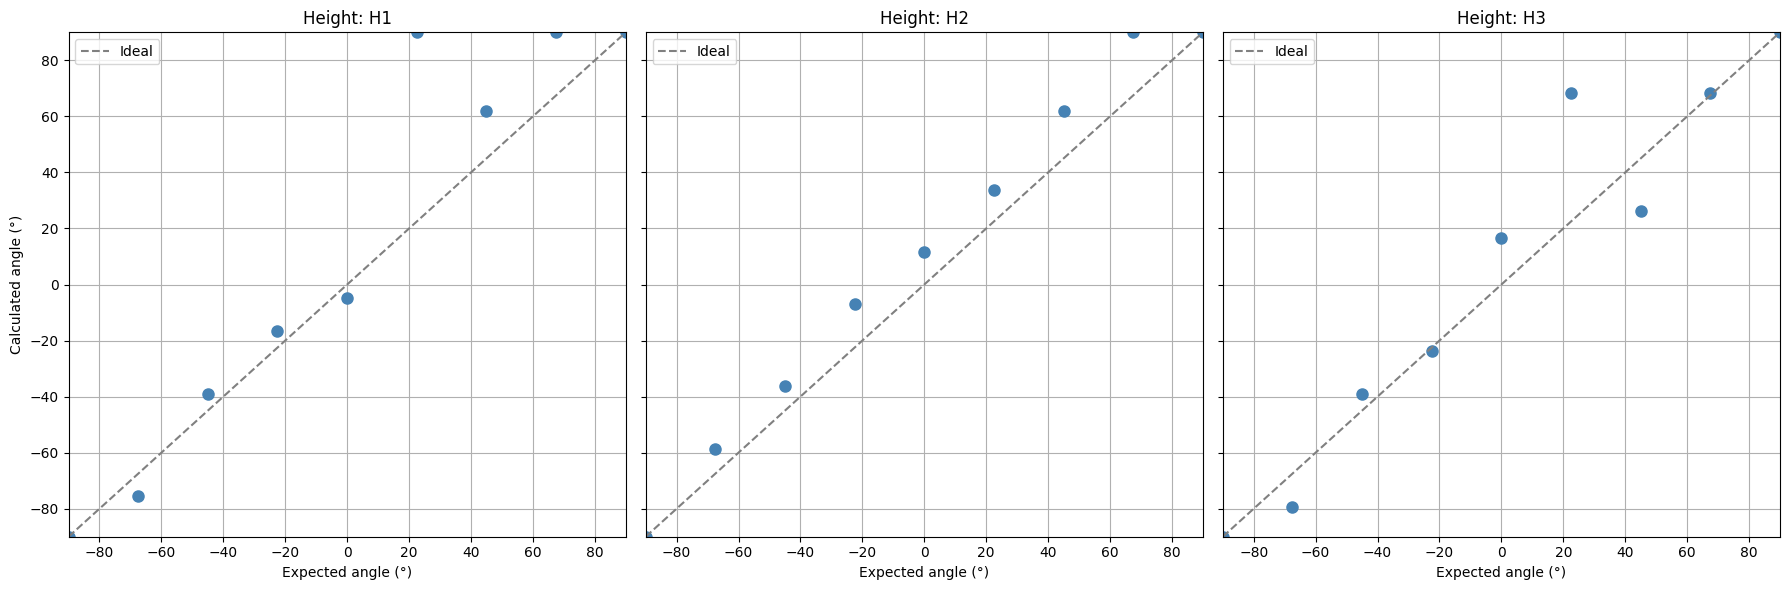

In [21]:
fig, axes = plt.subplots(1, n_heights, figsize=(6*n_heights, 6), sharex=True, sharey=True)

if n_heights == 1:
    axes = [axes]

for ax, height in zip(axes, heights_list):
    angle_data = results[height]
    
    sorted_angles = sorted(angle_data.keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    calculated = [angle_data[a]['calculated'] for a in sorted_angles]
    
    print(f"{height}: expected={expected}")
    print(f"{height}: calculated={calculated}")
    
    ax.plot(expected, calculated, 'o', color='steelblue', markersize=8)
    ax.plot([-90, 90], [-90, 90], '--', color='gray', label='Ideal')
    
    ax.set_xlabel('Expected angle (°)')
    ax.set_title(f'Height: {height}')
    ax.set_xlim(-90, 90)
    ax.set_ylim(-90, 90)
    ax.grid(True)
    ax.legend()

axes[0].set_ylabel('Calculated angle (°)')
plt.tight_layout()
plt.show()

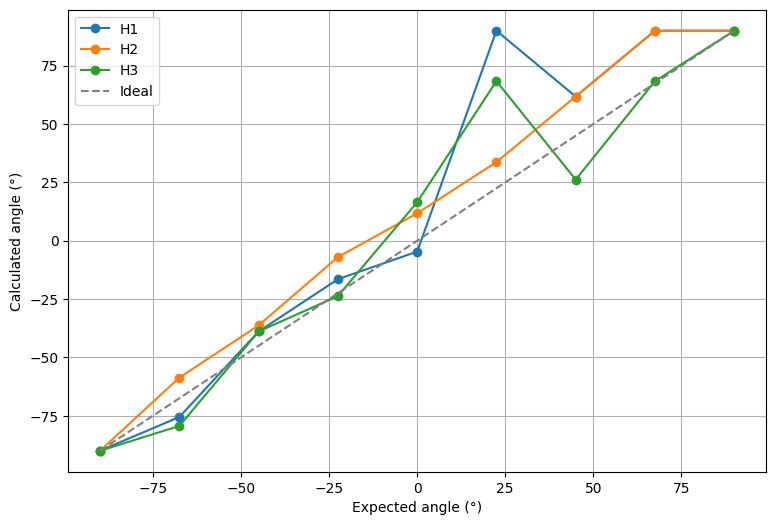

In [24]:
fig, ax = plt.subplots(figsize=(9, 6))
for height in heights_list:
    sorted_angles = sorted(results[height].keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    calculated = [results[height][a]['calculated'] for a in sorted_angles]
    ax.plot(expected, calculated, 'o-', label=height)
ax.plot([-90,90],[-90,90],'--', color='gray', label='Ideal')
ax.set_xlabel('Expected angle (°)'); ax.set_ylabel('Calculated angle (°)')
ax.legend(); ax.grid(True)
plt.show()

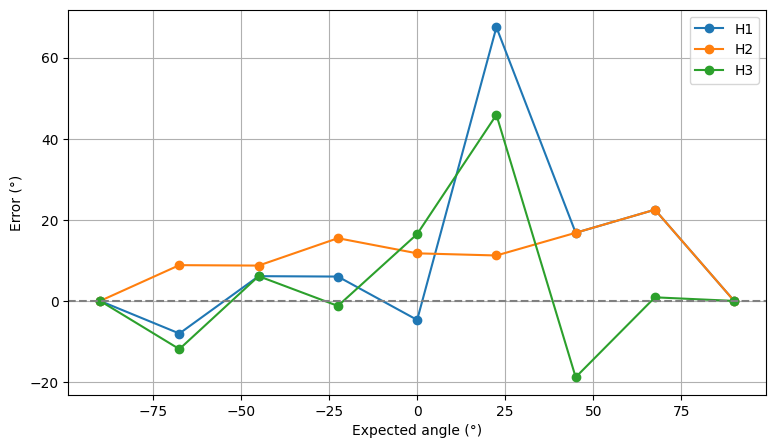

In [25]:
fig, ax = plt.subplots(figsize=(9, 5))
for height in heights_list:
    sorted_angles = sorted(results[height].keys(), key=lambda x: float(x))
    expected = [float(a) for a in sorted_angles]
    error = [results[height][a]['calculated'] - float(a) for a in sorted_angles]
    ax.plot(expected, error, 'o-', label=height)
ax.axhline(0, color='gray', linestyle='--')
ax.set_xlabel('Expected angle (°)'); ax.set_ylabel('Error (°)')
ax.legend(); ax.grid(True)
plt.show()

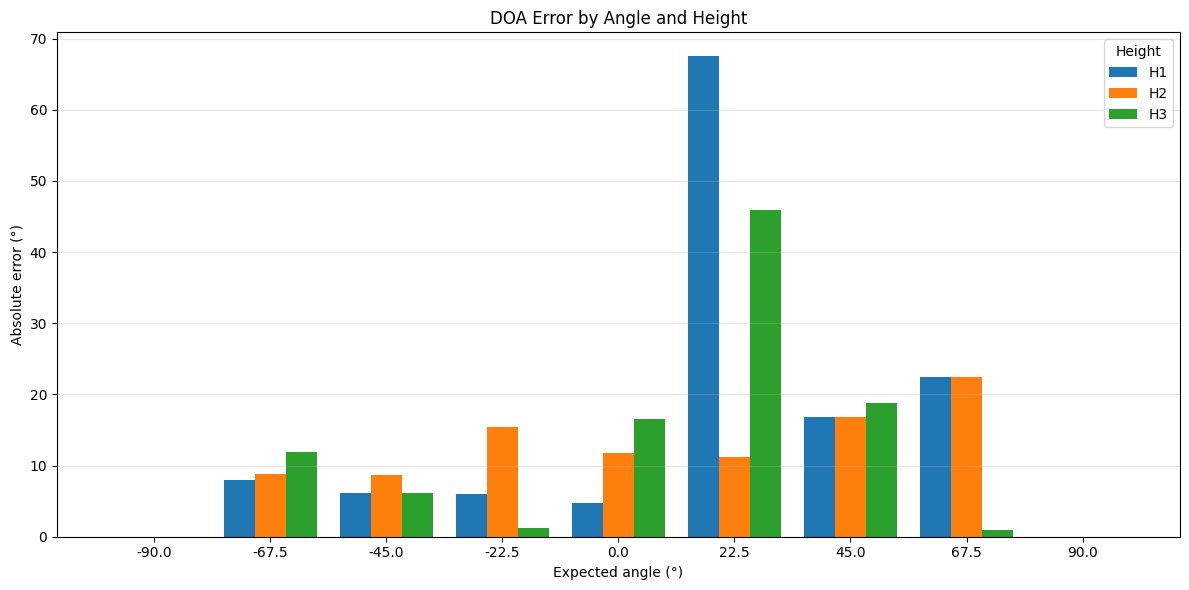

In [26]:
import numpy as np

heights_list = list(results.keys())
angles_list = sorted([float(a) for a in results[heights_list[0]].keys()])

fig, ax = plt.subplots(figsize=(12, 6))

x = np.arange(len(angles_list))
width = 0.8 / len(heights_list)

for i, height in enumerate(heights_list):
    errors = []
    for angle in angles_list:
        key = str(angle) if str(angle) in results[height] else str(int(angle))
        error = abs(results[height][key]['calculated'] - angle)
        errors.append(error)
    
    ax.bar(x + i*width, errors, width, label=height)

ax.set_xlabel('Expected angle (°)')
ax.set_ylabel('Absolute error (°)')
ax.set_title('DOA Error by Angle and Height')
ax.set_xticks(x + width * (len(heights_list)-1) / 2)
ax.set_xticklabels(angles_list)
ax.legend(title='Height')
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()